# BÀI TẬP NÂNG CAO với mô hình SARIMA – Dataset 2 (AirPassengers)

## Bước 7. So sánh với ARIMA (không có thành phần mùa vụ)

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.statespace.sarimax import SARIMAX
from sklearn.metrics import mean_absolute_error, mean_squared_error

warnings.filterwarnings("ignore")

URL = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/airline-passengers.csv"
S = 12           # chu kỳ mùa vụ
TEST_SIZE = 24   # 2 năm cuối làm tập kiểm tra

df = pd.read_csv(URL)
df.columns = ["Month", "Passengers"]
df["Month"] = pd.to_datetime(df["Month"])
y = df.set_index("Month")["Passengers"].asfreq("MS")
train, test = y.iloc[:-TEST_SIZE], y.iloc[-TEST_SIZE:]
print(y.shape)
y.head()

(144,)


Month
1949-01-01    112
1949-02-01    118
1949-03-01    132
1949-04-01    129
1949-05-01    121
Freq: MS, Name: Passengers, dtype: int64

In [2]:
sarima = SARIMAX(train,
                 order=(0, 1, 1),
                 seasonal_order=(0, 1, 1, S),
                 enforce_stationarity=False,
                 enforce_invertibility=False).fit(disp=False)

In [3]:
def evaluate(true, pred, name):
    mae = mean_absolute_error(true, pred)
    rmse = np.sqrt(mean_squared_error(true, pred))
    print(f"{name:>8}: MAE = {mae:8.3f} | RMSE = {rmse:8.3f}")
    return mae, rmse

In [4]:
pred_sarima = sarima.get_forecast(steps=TEST_SIZE).predicted_mean
res_sarima = evaluate(test, pred_sarima, "SARIMA")

  SARIMA: MAE =   66.275 | RMSE =   71.829


### Chọn ARIMA(p,1,q) tốt nhất theo AIC

In [5]:
best_aic, best_order = np.inf, None
for p in range(0, 4):
    for q in range(0, 4):
        try:
            m = SARIMAX(train, order=(p, 1, q)).fit(disp=False)
            if m.aic < best_aic:
                best_aic, best_order = m.aic, (p, 1, q)
        except Exception:
            continue
print(f"ARIMA tốt nhất theo AIC: order = {best_order}, AIC = {best_aic:.2f}")

ARIMA tốt nhất theo AIC: order = (3, 1, 3), AIC = 1089.76


In [6]:
arima = SARIMAX(train, order=best_order).fit(disp=False)
pred_arima = arima.get_forecast(steps=TEST_SIZE).predicted_mean
res_arima = evaluate(test, pred_arima, "ARIMA")

comparison = pd.DataFrame(
    {"MAE": [res_arima[0], res_sarima[0]],
     "RMSE": [res_arima[1], res_sarima[1]]},
    index=[f"ARIMA{best_order}", "SARIMA(0,1,1)(0,1,1,12)"])
comparison.round(3)

   ARIMA: MAE =   64.012 | RMSE =   88.160


,MAE,RMSE
"ARIMA(3, 1, 3)",64.012,88.160
"SARIMA(0,1,1)(0,1,1,12)",66.275,71.829


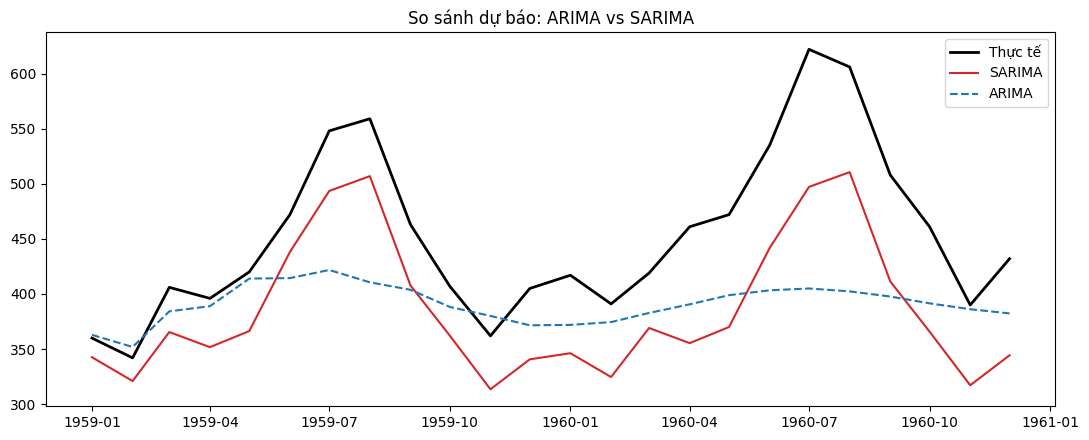

In [7]:
plt.figure(figsize=(11, 4.5))
plt.plot(test, label="Thực tế", color="black", lw=2)
plt.plot(pred_sarima, label="SARIMA", color="tab:red")
plt.plot(pred_arima, label="ARIMA", color="tab:blue", ls="--")
plt.legend(); plt.title("So sánh dự báo: ARIMA vs SARIMA")
plt.tight_layout(); plt.show()

**Kết luận:** ARIMA không mô hình hóa được mùa vụ nên dự báo gần như một đường xu hướng, còn SARIMA bám sát các đỉnh/đáy theo mùa → sai số (MAE, RMSE) thấp hơn.